# Modelado predictivo de la demanda de ECOBICI

## Objetivo

Desarrollar y evaluar modelos predictivos que estimen los movimientos diarios promedio de una estación ECOBICI a partir de nueve características de su entorno urbano.

Se utilizarán las estaciones con registros durante los 12 meses de octubre de 2025 a septiembre de 2026.

Los modelos se compararán con un esquema de validación espacial, buscando evaluar su capacidad de generalización a ubicaciones no utilizadas durante el entrenamiento.

El modelo seleccionado se utilizará posteriormente para estimar la demanda potencial de nuevas estaciones en las cuadrículas candidatas de 250 × 250 metros.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
datos = pd.read_csv(
    "../Data/Procesados/datos_modelo_ECOBICI.csv"
)

print("Dimensiones:", datos.shape)
datos.head()

Dimensiones: (670, 16)


,num_cicloe,alcaldia,latitud,longitud,poblacion_500m,negocios_500m,personal_500m,dist_metro,dist_metrobus,infra_ciclista_500m,estaciones_ecobici_500m,universidades_500m,dist_centro,movimientos_anuales,meses_con_datos,movimientos_diarios
0,423,Benito Juarez,19.367816,-99.175269,15499,687,7297.0,654.006187,566.793807,4679.191246,9,0,8420.129925,20945,12,57.383562
1,437,Benito Juarez,19.364916,-99.175985,11467,466,6432.5,666.650663,613.331841,3281.089280,7,1,8733.404864,17661,12,48.386301
2,438,Benito Juarez,19.364730,-99.174447,13056,394,6792.5,530.016121,775.154746,3429.599331,10,0,8669.272381,20973,12,57.460274
3,439,Benito Juarez,19.362037,-99.172683,9521,618,11198.0,205.474875,1011.945411,1053.003995,6,1,8840.315514,24073,12,65.953425
4,440,Benito Juarez,19.361699,-99.171387,8310,743,10221.5,66.784841,1152.921356,956.930808,7,1,8810.613919,45461,12,124.550685


In [4]:
predictoras = [
    "poblacion_500m",
    "negocios_500m",
    "personal_500m",
    "dist_metro",
    "dist_metrobus",
    "infra_ciclista_500m",
    "estaciones_ecobici_500m",
    "universidades_500m",
    "dist_centro"
]

X = datos[predictoras].copy()
y = datos["movimientos_diarios"].copy()

print("X:", X.shape)
print("y:", y.shape)

print("\nValores faltantes en X:", X.isna().sum().sum())
print("Valores faltantes en y:", y.isna().sum())

print("\nCoordenadas disponibles:")
print(datos[["latitud", "longitud"]].isna().sum())

X: (670, 9)
y: (670,)

Valores faltantes en X: 0
Valores faltantes en y: 0

Coordenadas disponibles:
latitud     0
longitud    0
dtype: int64


In [7]:
import geopandas as gpd
from sklearn.model_selection import GroupKFold

# Convertir coordenadas a metros
geo = gpd.GeoDataFrame(
    datos,
    geometry=gpd.points_from_xy(datos.longitud, datos.latitud),
    crs="EPSG:4326"
).to_crs(epsg=32614)

# Crear bloques espaciales de 2 km
tam_bloque = 2000

bloque_x = ((geo.geometry.x - geo.geometry.x.min()) // tam_bloque).astype(int)
bloque_y = ((geo.geometry.y - geo.geometry.y.min()) // tam_bloque).astype(int)

grupos = bloque_x.astype(str) + "_" + bloque_y.astype(str)

print("Bloques geográficos:", grupos.nunique())
print("Estaciones por bloque:")
print(grupos.value_counts().describe())

Bloques geográficos: 28
Estaciones por bloque:
count    28.000000
mean     23.928571
std      15.155805
min       1.000000
25%      17.000000
50%      25.000000
75%      30.250000
max      67.000000
Name: count, dtype: float64


In [8]:
cv_espacial = GroupKFold(n_splits=5)

for i, (train_idx, test_idx) in enumerate(
    cv_espacial.split(X, y, groups=grupos), start=1
):
    print(
        f"Fold {i}: "
        f"{len(train_idx)} entrenamiento, "
        f"{len(test_idx)} evaluación"
    )

Fold 1: 538 entrenamiento, 132 evaluación
Fold 2: 538 entrenamiento, 132 evaluación
Fold 3: 535 entrenamiento, 135 evaluación
Fold 4: 534 entrenamiento, 136 evaluación
Fold 5: 535 entrenamiento, 135 evaluación


In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score

modelo_base = DummyRegressor(strategy="median")

mae_base = -cross_val_score(
    modelo_base,
    X,
    y,
    groups=grupos,
    cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

print("MAE por fold:", mae_base.round(2))
print("MAE promedio:", round(mae_base.mean(), 2))
print("Desviación estándar:", round(mae_base.std(), 2))

MAE por fold: [104.11  72.26  53.09  73.02  50.96]
MAE promedio: 70.69
Desviación estándar: 19.1


In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

modelo_lineal = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

mae_lineal = -cross_val_score(
    modelo_lineal,
    X,
    y,
    groups=grupos,
    cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

print("MAE por fold:", mae_lineal.round(2))
print("MAE promedio:", round(mae_lineal.mean(), 2))
print("Desviación estándar:", round(mae_lineal.std(), 2))

print(
    "Mejora respecto al modelo base:",
    round((1 - mae_lineal.mean() / mae_base.mean()) * 100, 2),
    "%"
)

MAE por fold: [70.22 56.71 48.54 73.41 54.78]
MAE promedio: 60.73
Desviación estándar: 9.5
Mejora respecto al modelo base: 14.09 %


In [11]:
from sklearn.ensemble import RandomForestRegressor

modelo_rf = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

mae_rf = -cross_val_score(
    modelo_rf,
    X,
    y,
    groups=grupos,
    cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

print("MAE por fold:", mae_rf.round(2))
print("MAE promedio:", round(mae_rf.mean(), 2))
print("Desviación estándar:", round(mae_rf.std(), 2))

print(
    "Mejora respecto a regresión lineal:",
    round((1 - mae_rf.mean() / mae_lineal.mean()) * 100, 2),
    "%"
)

MAE por fold: [67.51 51.96 50.37 62.48 51.05]
MAE promedio: 56.67
Desviación estándar: 6.99
Mejora respecto a regresión lineal: 6.68 %


MAE global: 56.66


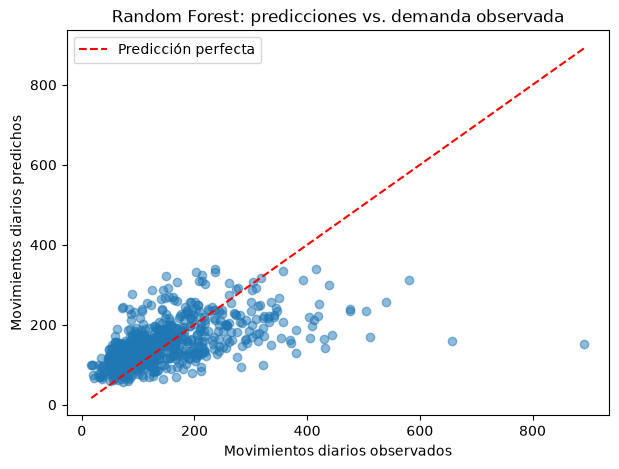

In [12]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

predicciones_rf = np.empty(len(y))

for train_idx, test_idx in cv_espacial.split(X, y, groups=grupos):
    modelo = clone(modelo_rf)

    modelo.fit(X.iloc[train_idx], y.iloc[train_idx])

    predicciones_rf[test_idx] = modelo.predict(X.iloc[test_idx])

print("MAE global:", round(mean_absolute_error(y, predicciones_rf), 2))

plt.figure(figsize=(7, 5))

plt.scatter(y, predicciones_rf, alpha=0.5)
plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    "r--",
    label="Predicción perfecta"
)

plt.xlabel("Movimientos diarios observados")
plt.ylabel("Movimientos diarios predichos")
plt.title("Random Forest: predicciones vs. demanda observada")
plt.legend()
plt.show()

In [13]:
from sklearn.ensemble import GradientBoostingRegressor

modelo_gb = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=5,
    random_state=42
)

mae_gb = -cross_val_score(
    modelo_gb,
    X,
    y,
    groups=grupos,
    cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

print("MAE por fold:", mae_gb.round(2))
print("MAE promedio:", round(mae_gb.mean(), 2))
print("Desviación estándar:", round(mae_gb.std(), 2))

print(
    "Mejora respecto a Random Forest:",
    round((1 - mae_gb.mean() / mae_rf.mean()) * 100, 2),
    "%"
)

MAE por fold: [65.86 57.55 47.05 65.81 52.39]
MAE promedio: 57.73
Desviación estándar: 7.4
Mejora respecto a Random Forest: -1.87 %


In [14]:
from sklearn.linear_model import Ridge

modelo_ridge = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10)
)

mae_ridge = -cross_val_score(
    modelo_ridge,
    X,
    y,
    groups=grupos,
    cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

print("MAE por fold:", mae_ridge.round(2))
print("MAE promedio:", round(mae_ridge.mean(), 2))
print("Desviación estándar:", round(mae_ridge.std(), 2))

print(
    "Mejora respecto a regresión lineal:",
    round((1 - mae_ridge.mean() / mae_lineal.mean()) * 100, 2),
    "%"
)

MAE por fold: [69.56 54.7  48.51 73.59 54.16]
MAE promedio: 60.1
Desviación estándar: 9.7
Mejora respecto a regresión lineal: 1.03 %


In [15]:
resultados_rf = pd.DataFrame({
    "observado": y.to_numpy(),
    "predicho": predicciones_rf
})

umbral = resultados_rf["observado"].quantile(0.90)

resultados_rf["grupo"] = np.where(
    resultados_rf["observado"] >= umbral,
    "10% mayor demanda",
    "90% restante"
)

resultados_rf["error_absoluto"] = abs(
    resultados_rf["observado"] - resultados_rf["predicho"]
)

resultados_rf.groupby("grupo").agg(
    estaciones=("observado", "count"),
    demanda_real=("observado", "mean"),
    demanda_predicha=("predicho", "mean"),
    MAE=("error_absoluto", "mean")
).round(2)

,estaciones,demanda_real,demanda_predicha,MAE
grupo,,,,
10% mayor demanda,67,368.55,213.01,156.02
90% restante,603,127.68,147.51,45.61


In [16]:
from sklearn.model_selection import cross_val_predict

# Predicciones espaciales fuera de muestra para Gradient Boosting
predicciones_gb = cross_val_predict(
    modelo_gb, X, y,
    cv=cv_espacial,
    groups=grupos
)

# Comparar los modelos
k = int(np.ceil(len(y) * 0.10))
top_real = set(np.argsort(y.to_numpy())[-k:])

for nombre, pred in [
    ("Random Forest", predicciones_rf),
    ("Gradient Boosting", predicciones_gb)
]:
    top_predicho = set(np.argsort(pred)[-k:])

    precision = len(top_real & top_predicho) / k

    print(f"{nombre}:")
    print(f"  Precision@10%: {precision:.2%}")
    print(f"  Estaciones correctamente identificadas: {len(top_real & top_predicho)}/{k}")

Random Forest:
  Precision@10%: 31.34%
  Estaciones correctamente identificadas: 21/67
Gradient Boosting:
  Precision@10%: 31.34%
  Estaciones correctamente identificadas: 21/67


In [17]:
from sklearn.model_selection import GridSearchCV, cross_val_score

parametros_rf = {
    "n_estimators": [150, 300],
    "max_depth": [None, 10],
    "min_samples_leaf": [3, 7]
}

busqueda_rf = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=parametros_rf,
    scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=3),
    n_jobs=-1
)

# Validación espacial anidada
mae_rf_optimizado = []

for train_idx, test_idx in cv_espacial.split(X, y, groups=grupos):
    busqueda_rf.fit(
        X.iloc[train_idx],
        y.iloc[train_idx],
        groups=grupos.iloc[train_idx]
    )

    pred = busqueda_rf.predict(X.iloc[test_idx])

    mae_rf_optimizado.append(
        mean_absolute_error(y.iloc[test_idx], pred)
    )

mae_rf_optimizado = np.array(mae_rf_optimizado)

print("MAE por fold:", mae_rf_optimizado.round(2))
print("MAE promedio:", round(mae_rf_optimizado.mean(), 2))
print("Desviación estándar:", round(mae_rf_optimizado.std(), 2))

MAE por fold: [67.16 49.77 50.37 65.02 51.93]
MAE promedio: 56.85
Desviación estándar: 7.61


In [18]:
from sklearn.model_selection import GridSearchCV

parametros_gb = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3]
}

busqueda_gb = GridSearchCV(
    GradientBoostingRegressor(
        min_samples_leaf=5,
        random_state=42
    ),
    param_grid=parametros_gb,
    scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=3),
    n_jobs=-1
)

mae_gb_optimizado = []

for train_idx, test_idx in cv_espacial.split(X, y, groups=grupos):

    busqueda_gb.fit(
        X.iloc[train_idx],
        y.iloc[train_idx],
        groups=grupos.iloc[train_idx]
    )

    pred = busqueda_gb.predict(X.iloc[test_idx])

    mae_gb_optimizado.append(
        mean_absolute_error(y.iloc[test_idx], pred)
    )

mae_gb_optimizado = np.array(mae_gb_optimizado)

print("MAE por fold:", mae_gb_optimizado.round(2))
print("MAE promedio:", round(mae_gb_optimizado.mean(), 2))
print("Desviación estándar:", round(mae_gb_optimizado.std(), 2))

MAE por fold: [66.87 58.5  51.27 66.24 50.72]
MAE promedio: 58.72
Desviación estándar: 6.96


In [19]:
from sklearn.inspection import permutation_importance

importancias = []

for train_idx, test_idx in cv_espacial.split(X, y, groups=grupos):
    modelo = clone(modelo_rf)
    modelo.fit(X.iloc[train_idx], y.iloc[train_idx])

    resultado = permutation_importance(
        modelo,
        X.iloc[test_idx],
        y.iloc[test_idx],
        scoring="neg_mean_absolute_error",
        n_repeats=3,
        random_state=42
    )

    importancias.append(resultado.importances_mean)

importancia_variables = pd.Series(
    np.mean(importancias, axis=0),
    index=predictoras
).sort_values(ascending=False)

print(importancia_variables.round(2))

dist_centro                10.29
dist_metro                  3.77
infra_ciclista_500m         2.81
personal_500m               1.52
dist_metrobus               1.25
poblacion_500m              1.14
estaciones_ecobici_500m     0.86
universidades_500m          0.17
negocios_500m              -0.10
dtype: float64


In [20]:
X_sin_centro = X.drop(columns="dist_centro")

mae_rf_sin_centro = -cross_val_score(
    modelo_rf, X_sin_centro, y,
    groups=grupos,
    cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

mae_gb_sin_centro = -cross_val_score(
    modelo_gb, X_sin_centro, y,
    groups=grupos,
    cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

print("Random Forest:")
print("Original:", round(mae_rf.mean(), 2))
print("Sin centro:", round(mae_rf_sin_centro.mean(), 2))

print("\nGradient Boosting:")
print("Original:", round(mae_gb.mean(), 2))
print("Sin centro:", round(mae_gb_sin_centro.mean(), 2))

Random Forest:
Original: 56.67
Sin centro: 61.18

Gradient Boosting:
Original: 57.73
Sin centro: 62.64


In [21]:
X_fe = X_sin_centro.copy()

# Distancia al transporte masivo más cercano
X_fe["dist_transporte"] = X_fe[
    ["dist_metro", "dist_metrobus"]
].min(axis=1)

# Personal ocupado promedio por establecimiento
X_fe["personal_por_negocio"] = (
    X_fe["personal_500m"] /
    X_fe["negocios_500m"].clip(lower=1)
)

# Interacción entre infraestructura y estaciones cercanas
X_fe["infra_x_estaciones"] = (
    X_fe["infra_ciclista_500m"] *
    X_fe["estaciones_ecobici_500m"]
)

print("Variables originales sin centro:", X_sin_centro.shape[1])
print("Variables con Feature Engineering:", X_fe.shape[1])

Variables originales sin centro: 8
Variables con Feature Engineering: 11


In [22]:
mae_rf_fe = -cross_val_score(
    modelo_rf, X_fe, y,
    groups=grupos,
    cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

mae_gb_fe = -cross_val_score(
    modelo_gb, X_fe, y,
    groups=grupos,
    cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

comparacion = pd.DataFrame({
    "Modelo": ["Random Forest", "Gradient Boosting"],
    "Original (9 variables)": [mae_rf.mean(), mae_gb.mean()],
    "Sin centro (8 variables)": [
        mae_rf_sin_centro.mean(),
        mae_gb_sin_centro.mean()
    ],
    "Con Feature Engineering (11 variables)": [
        mae_rf_fe.mean(),
        mae_gb_fe.mean()
    ]
})

print(comparacion.round(2))
print("\nRF por fold:", mae_rf_fe.round(2))
print("GB por fold:", mae_gb_fe.round(2))

              Modelo  Original (9 variables)  Sin centro (8 variables)  \
0      Random Forest                   56.67                     61.18   
1  Gradient Boosting                   57.73                     62.64   

   Con Feature Engineering (11 variables)  
0                                   60.99  
1                                   62.49  

RF por fold: [77.59 57.6  47.88 69.12 52.74]
GB por fold: [78.99 60.91 43.17 74.07 55.31]


In [23]:
analisis_centro = pd.DataFrame({
    "dist_centro": X["dist_centro"].to_numpy(),
    "real": y.to_numpy(),
    "predicho": predicciones_rf
})

analisis_centro["zona"] = pd.qcut(
    analisis_centro["dist_centro"],
    q=4,
    labels=[
        "1. Más céntricas",
        "2. Intermedias cercanas",
        "3. Intermedias lejanas",
        "4. Más alejadas"
    ]
)

analisis_centro["error"] = (
    analisis_centro["real"] - analisis_centro["predicho"]
)

analisis_centro["error_absoluto"] = (
    analisis_centro["error"].abs()
)

analisis_centro.groupby("zona", observed=True).agg(
    estaciones=("real", "count"),
    demanda_real=("real", "mean"),
    demanda_predicha=("predicho", "mean"),
    sesgo=("error", "mean"),
    MAE=("error_absoluto", "mean")
).round(2)

,estaciones,demanda_real,demanda_predicha,sesgo,MAE
zona,,,,,
1. Más céntricas,168,201.84,194.47,7.37,70.99
2. Intermedias cercanas,167,175.73,177.20,-1.47,67.95
3. Intermedias lejanas,167,134.59,136.91,-2.31,47.44
4. Más alejadas,168,94.96,107.70,-12.75,40.26


In [24]:
from sklearn.preprocessing import PolynomialFeatures

modelo_ridge_poli = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    Ridge(alpha=100)
)

mae_ridge_sin_centro = -cross_val_score(
    modelo_ridge, X_sin_centro, y,
    groups=grupos, cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

mae_ridge_poli = -cross_val_score(
    modelo_ridge_poli, X_sin_centro, y,
    groups=grupos, cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

print("Ridge original (9 variables):", round(mae_ridge.mean(), 2))
print("Ridge sin centro (8 variables):", round(mae_ridge_sin_centro.mean(), 2))
print("Ridge polinómica sin centro:", round(mae_ridge_poli.mean(), 2))
print("\nMAE por fold:", mae_ridge_poli.round(2))

Ridge original (9 variables): 60.1
Ridge sin centro (8 variables): 63.0
Ridge polinómica sin centro: 60.63

MAE por fold: [69.35 53.01 51.89 74.57 54.35]


In [25]:
X_log = X_sin_centro.copy()

variables_log = [
    "poblacion_500m",
    "negocios_500m",
    "personal_500m",
    "infra_ciclista_500m",
    "estaciones_ecobici_500m",
    "universidades_500m"
]

for variable in variables_log:
    X_log[f"log_{variable}"] = np.log1p(X_log[variable])

mae_ridge_log = -cross_val_score(
    modelo_ridge,
    X_log,
    y,
    groups=grupos,
    cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

print("Ridge sin centro:", round(mae_ridge_sin_centro.mean(), 2))
print("Ridge polinómica:", round(mae_ridge_poli.mean(), 2))
print("Ridge con logaritmos:", round(mae_ridge_log.mean(), 2))

print("\nMAE por fold:", mae_ridge_log.round(2))

Ridge sin centro: 63.0
Ridge polinómica: 60.63
Ridge con logaritmos: 62.24

MAE por fold: [69.59 58.86 49.58 80.12 53.07]


In [26]:
mae_ridge_poli_centro = -cross_val_score(
    modelo_ridge_poli,
    X,
    y,
    groups=grupos,
    cv=cv_espacial,
    scoring="neg_mean_absolute_error"
)

print("Ridge original:", round(mae_ridge.mean(), 2))
print("Ridge polinómica sin centro:", round(mae_ridge_poli.mean(), 2))
print("Ridge polinómica con centro:", round(mae_ridge_poli_centro.mean(), 2))
print("Random Forest:", round(mae_rf.mean(), 2))

print("\nMAE por fold:", mae_ridge_poli_centro.round(2))

Ridge original: 60.1
Ridge polinómica sin centro: 60.63
Ridge polinómica con centro: 55.28
Random Forest: 56.67

MAE por fold: [62.09 47.23 51.37 61.76 53.94]


In [27]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline

modelo_poli = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    Ridge()
)

busqueda_poli = GridSearchCV(
    modelo_poli,
    param_grid={"ridge__alpha": [1, 10, 100, 1000]},
    scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=3)
)

mae_poli_anidado = []
alphas_elegidos = []

for train_idx, test_idx in cv_espacial.split(X, y, groups=grupos):
    busqueda_poli.fit(
        X.iloc[train_idx],
        y.iloc[train_idx],
        groups=grupos.iloc[train_idx]
    )

    pred = busqueda_poli.predict(X.iloc[test_idx])

    mae_poli_anidado.append(
        mean_absolute_error(y.iloc[test_idx], pred)
    )

    alphas_elegidos.append(
        busqueda_poli.best_params_["ridge__alpha"]
    )

print("MAE por fold:", np.round(mae_poli_anidado, 2))
print("MAE promedio:", round(np.mean(mae_poli_anidado), 2))
print("Alphas seleccionados:", alphas_elegidos)

MAE por fold: [62.99 47.14 51.71 69.66 49.26]
MAE promedio: 56.15
Alphas seleccionados: [100, 100, 100, 1000, 100]


## Conclusiones del modelado predictivo

### 1. Comparación de modelos

Se evaluaron cinco enfoques predictivos utilizando 670 estaciones ECOBICI, nueve variables explicativas y la demanda diaria promedio de octubre de 2025 a septiembre de 2026.

La evaluación utilizó validación cruzada espacial de cinco particiones, agrupando las estaciones en bloques geográficos de 2 × 2 km, y el error absoluto medio (MAE) como métrica principal.

| Modelo | MAE promedio |
|---|---:|
| Modelo base (mediana) | 70.69 |
| Regresión lineal | 60.73 |
| Ridge | 60.10 |
| Gradient Boosting | 57.73 |
| Random Forest | 56.67 |

Los modelos predictivos superaron al modelo base, lo que indica que las características del entorno urbano contienen información útil para estimar la actividad de ECOBICI.

### 2. Ingeniería de características

Se exploraron distintas estrategias para mejorar la capacidad predictiva:

- Eliminación de la distancia al centro.
- Construcción de variables relacionadas con transporte, actividad económica e infraestructura.
- Transformaciones logarítmicas.
- Incorporación de términos cuadráticos e interacciones mediante `PolynomialFeatures`.

La eliminación de `dist_centro` deterioró el desempeño de Random Forest y Gradient Boosting en aproximadamente un 8%, lo que confirma su relevancia predictiva.

Las tres variables adicionales construidas manualmente no produjeron mejoras sustanciales.

En cambio, la regresión Ridge con términos cuadráticos e interacciones obtuvo resultados prometedores, alcanzando un MAE exploratorio de 55.28 al conservar las nueve variables originales.

### 3. Optimización y validación espacial anidada

Se aplicó validación espacial anidada para separar la selección de hiperparámetros de la evaluación predictiva.

| Modelo | MAE con validación anidada |
|---|---:|
| Random Forest | 56.85 |
| Gradient Boosting | 58.72 |
| Ridge polinómica | **56.15** |

La Ridge polinómica obtuvo el menor MAE promedio en esta comparación, aunque su ventaja sobre Random Forest fue reducida.

En cuatro de las cinco particiones se seleccionó un parámetro de regularización `alpha=100`, mientras que en una se seleccionó `alpha=1000`.

### 4. Limitaciones identificadas

El análisis permitió identificar tres limitaciones relevantes:

**Predicción de demanda alta:** Random Forest mostró dificultades para estimar la actividad de las estaciones con mayor demanda. Tanto Random Forest como Gradient Boosting identificaron correctamente 21 de las 67 estaciones pertenecientes al 10% de mayor actividad.

**Dependencia geográfica:** la distancia al centro fue la variable con mayor importancia predictiva en Random Forest. Aunque no se observó una subestimación sistemática de las estaciones existentes más alejadas, esto no garantiza un comportamiento adecuado en ubicaciones donde ECOBICI todavía no opera.

**Generalización:** los modelos se entrenaron con estaciones existentes, cuyas ubicaciones responden a decisiones previas de expansión. Por ello, las predicciones para nuevas zonas deberán interpretarse con cautela. Asimismo, la exploración repetida de modelos sobre los mismos folds limita la independencia de las comparaciones realizadas.

### 5. Conclusión y siguientes pasos

Se conservarán **Random Forest y Ridge polinómica como modelos candidatos** para estimar demanda.

La selección definitiva dependerá no solamente del MAE, sino también del comportamiento de ambos modelos en ubicaciones candidatas, particularmente en zonas alejadas del centro y con baja presencia actual de ECOBICI.

La siguiente etapa consistirá en construir las variables explicativas para las cuadrículas candidatas de 250 × 250 metros, comparar sus características con las estaciones existentes y evaluar la plausibilidad de las predicciones antes de incorporarlas al modelo de optimización.

Las recomendaciones finales integrarán demanda estimada, cobertura poblacional incremental y conectividad de la red.